# Temperature Sensor Analysis and Fusion

Calculate the mean and variance for each sensor from a calibration log. Test basic averaging vs. inverse-variance weighting to fuse the sensors. Use the factory-calibrated TMP117 readings as the assumed ground truth. 

Press `shift + enter` to run each cell.

In [3]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import utils

## Settings

In [4]:
# Recording (folders containing temp.csv and meta.json)
RECORDING_CAL_PATH = "recordings/static_cal"
RECORDING_EVAL_PATH = "recordings/static_eval"

## Analyze Raw Readings

In [5]:
# Load both recordings
cal, cal_meta = utils.load_recording(RECORDING_CAL_PATH)
ev, ev_meta = utils.load_recording(RECORDING_EVAL_PATH)
print(f"Num calibration samples: {cal["t_us"].shape}")
print(f"Num evaluation samples: {ev["t_us"].shape}")

Num calibration samples: (301,)
Num evaluation samples: (301,)


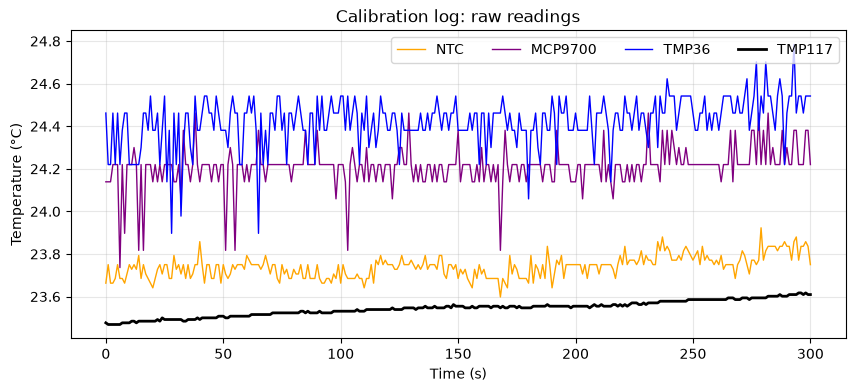

In [12]:
# Plot sensor values over time
utils.plot_series(
    cal["t"],
    [
        ("NTC", cal["ntc_c"], "orange"),
        ("MCP9700", cal["mcp9700_c"], "purple"),
        ("TMP36", cal["tmp36_c"], "blue"),
        ("TMP117", cal["tmp117_c"], "k"),
    ],
    title="Calibration log: raw readings",
)

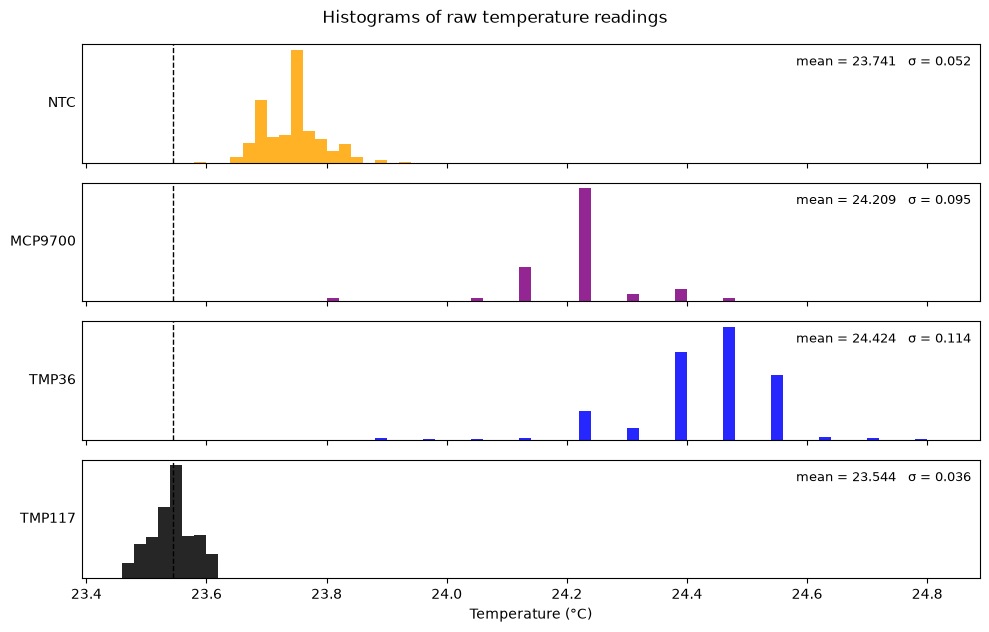

In [16]:
# Plot histograms of sensor values
utils.plot_histograms(
    [
        ("NTC", cal["ntc_c"], "orange"),
        ("MCP9700", cal["mcp9700_c"], "purple"),
        ("TMP36", cal["tmp36_c"], "blue"),
        ("TMP117", cal["tmp117_c"], "k"),
    ],
    ref_value=np.mean(cal["tmp117_c"]),
    title="Histograms of raw temperature readings",
    xlabel="Temperature (°C)",
)

In [41]:
# Print means and standard deviations
print(f"NTC mean: {np.mean(cal["ntc_c"]):.3f} std dev: {np.std(cal["ntc_c"]):.3f}")
print(f"MCP9700 mean: {np.mean(cal["mcp9700_c"]):.3f} std dev: {np.std(cal["mcp9700_c"]):.3f}")
print(f"TMP36 mean: {np.mean(cal["tmp36_c"]):.3f} std dev: {np.std(cal["tmp36_c"]):.3f}")
print(f"TMP117 mean: {np.mean(cal["tmp117_c"]):.3f} std dev: {np.std(cal["tmp117_c"]):.3f}")

NTC mean: 23.741 std dev: 0.052
MCP9700 mean: 24.209 std dev: 0.095
TMP36 mean: 24.424 std dev: 0.114
TMP117 mean: 23.544 std dev: 0.035


## Fusion: Simple Average and Calibrate

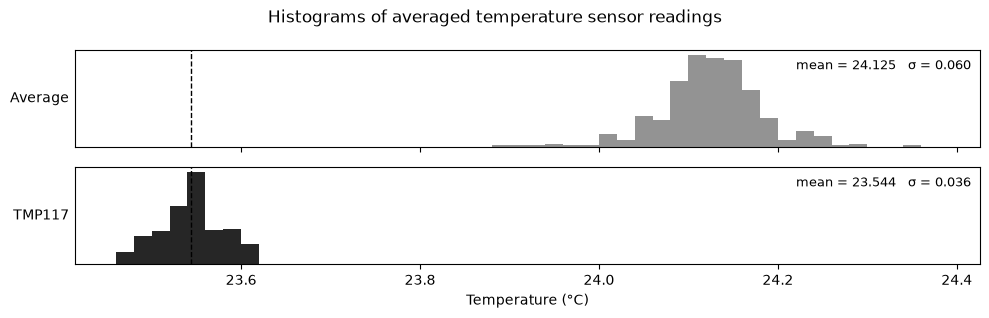

In [48]:
# Naive approach: simple average (mean) of the raw readings (no calibration)
avgs = np.mean([cal["ntc_c"], cal["mcp9700_c"], cal["tmp36_c"]], axis=0)

# Plot histograms of naive averaging vs. TMP117
utils.plot_histograms(
    [
        ("Average", avgs, "gray"),
        ("TMP117", cal["tmp117_c"], "k"),
    ],
    ref_value=np.mean(cal["tmp117_c"]),
    title="Histograms of averaged temperature sensor readings",
    xlabel="Temperature (°C)",
)

In [58]:
# Find the average bias (offset) for each sensor vs. TMP117
ntc_offset = np.mean(cal["ntc_c"] - cal["tmp117_c"])
mcp_offset = np.mean(cal["mcp9700_c"] - cal["tmp117_c"])
tmp_offset = np.mean(cal["tmp36_c"] - cal["tmp117_c"])

# Print offsets
print(f"NTC offset: {ntc_offset:.4f}")
print(f"MCP9700 offset: {mcp_offset:.4f}")
print(f"TMP36 offset: {tmp_offset:.4f}")

NTC offset: 0.1969
MCP9700 offset: 0.6655
TMP36 offset: 0.8797


In [59]:
# Apply the offsets to the evaluation log
ntc_cal = ev["ntc_c"] - ntc_offset
mcp_cal = ev["mcp9700_c"] - mcp_offset
tmp_cal = ev["tmp36_c"] - tmp_offset

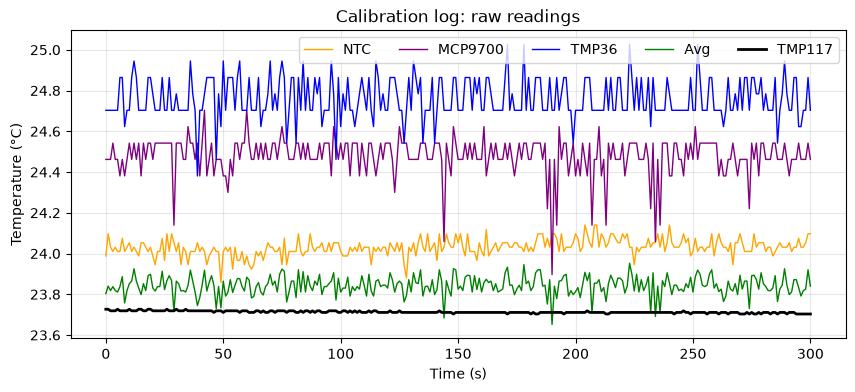

In [67]:
# Repeat the averaging fusion but with the calibrated eval data
avgs_cal = np.mean([ntc_cal, mcp_cal, tmp_cal], axis=0)

# Plot calibrated sensor values vs. averaging fusion vs. original TMP117
utils.plot_series(
    cal["t"],
    [
        ("NTC", ntc_cal, "orange"),
        ("MCP9700", mcp_cal, "purple"),
        ("TMP36", tmp_cal, "blue"),
        ("Avg", avgs_cal, "green"),
        ("TMP117", ev["tmp117_c"], "k"),
    ],
    title="Calibration log: raw readings",
)

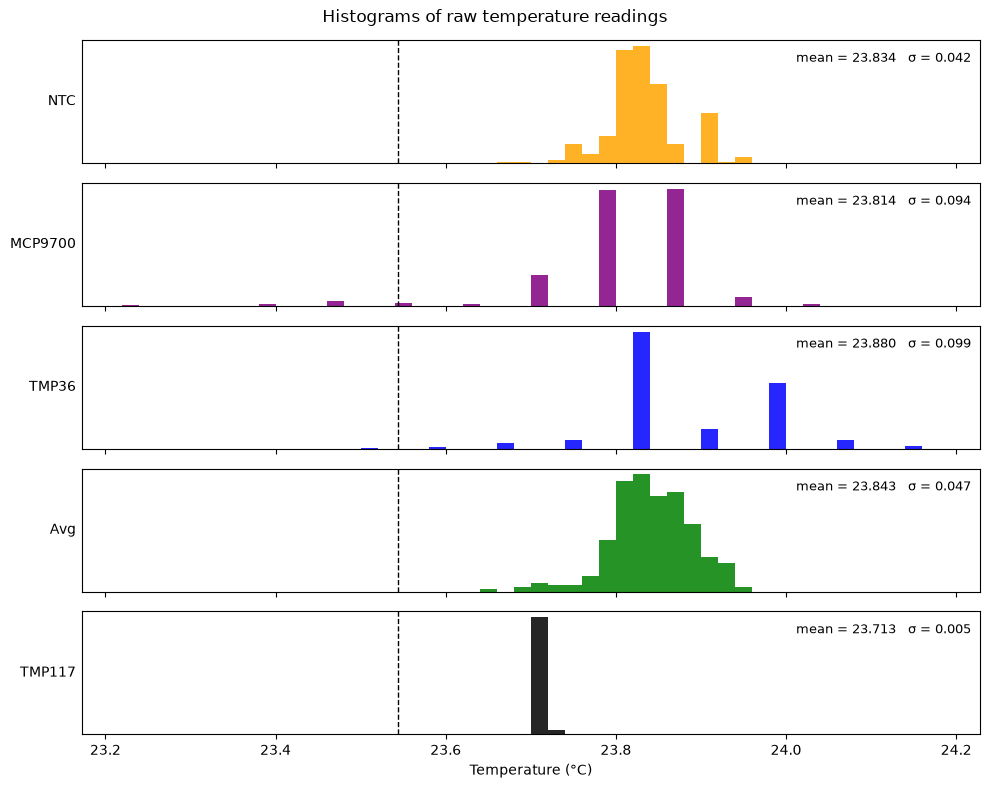

In [65]:
# Plot histograms of calibrated sensor values
utils.plot_histograms(
    [
        ("NTC", ntc_cal, "orange"),
        ("MCP9700", mcp_cal, "purple"),
        ("TMP36", tmp_cal, "blue"),
        ("Avg", avgs_cal, "green"),
        ("TMP117", ev["tmp117_c"], "k"),
    ],
    ref_value=np.mean(cal["tmp117_c"]),
    title="Histograms of raw temperature readings",
    xlabel="Temperature (°C)",
)

In [66]:
# Print mean and std devs for calibrated data
print(f"Calibrated NTC mean: {np.mean(ntc_cal):.3f} std dev: {np.std(ntc_cal):.3f}")
print(f"MCP9700 mean: {np.mean(mcp_cal):.3f} std dev: {np.std(mcp_cal):.3f}")
print(f"TMP36 mean: {np.mean(tmp_cal):.3f} std dev: {np.std(tmp_cal):.3f}")
print(f"Avg Fusion mean: {np.mean(avgs_cal):.3f} std dev: {np.std(avgs_cal):.3f}")
print(f"TMP117 mean: {np.mean(ev["tmp117_c"]):.3f} std dev: {np.std(ev["tmp117_c"]):.3f}")

Calibrated NTC mean: 23.834 std dev: 0.041
MCP9700 mean: 23.814 std dev: 0.094
TMP36 mean: 23.880 std dev: 0.099
Avg Fusion mean: 23.843 std dev: 0.047
TMP117 mean: 23.713 std dev: 0.005


In [68]:
# TODO: redo measurements? TMP117 mean is now off from avg-cal fusion?